| Inicio | Anterior |
| --- | --- |
| [🏠](../README.md) | [⏪](../21_MATEMATICA_MAS_AVANZADA/21_2_Analisis_funcional.ipynb) |

# 21.3 PDE AVANZADA: SOLUCIONES DÉBILES, ENERGÍA Y ESTABILIDAD

Al estudiar PDEs avanzadas cambia una pregunta básica: una solución puede no tener todas las derivadas clásicas que aparecen en la ecuación, pero seguir representando correctamente balances físicos. Para trabajar con ella necesitamos espacios de funciones, integración por partes y criterios que distingan soluciones admisibles.

Veremos tres casos: difusión y sus estimaciones de energía, una ecuación elíptica con coeficiente discontinuo y Burgers con shocks y rarefacciones. Finalmente analizaremos por qué un residual pequeño en unos puntos puede engañar a un método informado por física.

**Objetivos.** Formular soluciones débiles, entender bien planteamiento, verificar conservación y conectar teoría con pérdidas SciML. Bibliotecas: NumPy, SciPy y Matplotlib. Requisitos: PDE básica, integración por partes y nociones de Sobolev.

## 1. Bien planteamiento según Hadamard

Un problema está bien planteado en unos espacios dados si tiene solución, esa solución es única y depende continuamente de los datos. La dependencia continua debe indicar norma: un pequeño error en una norma puede no ser pequeño en otra.

El calor hacia adelante suaviza perturbaciones y es estable en $L^2$ bajo condiciones apropiadas. El calor hacia atrás intenta reconstruir frecuencias que la difusión casi eliminó y es inestable sin restricciones o regularización. Esta diferencia aparece directamente en problemas inversos y modelos aprendidos.

## 2. Energía del calor y unicidad

Para $u_t=\alpha u_{xx}$ en $(0,1)$ con $u=0$ en los extremos, definimos $E(t)=\frac12\int_0^1u^2\,dx$. Multiplicando por $u$ e integrando por partes,
$$\frac{dE}{dt}=\alpha\int uu_{xx}\,dx=-\alpha\int(u_x)^2\,dx\le0.$$
La frontera elimina el término $[uu_x]_0^1$. Esta identidad expresa disipación. Para la diferencia de dos soluciones con el mismo dato inicial, la energía empieza en cero y no puede crecer; por tanto la diferencia es cero y obtenemos unicidad en una clase donde el argumento se justifica.

Una solución débil requiere justificar la identidad con regularidad y funciones de prueba adecuadas. En un caso suave como el siguiente podemos verificar todas las cantidades con una solución exacta.

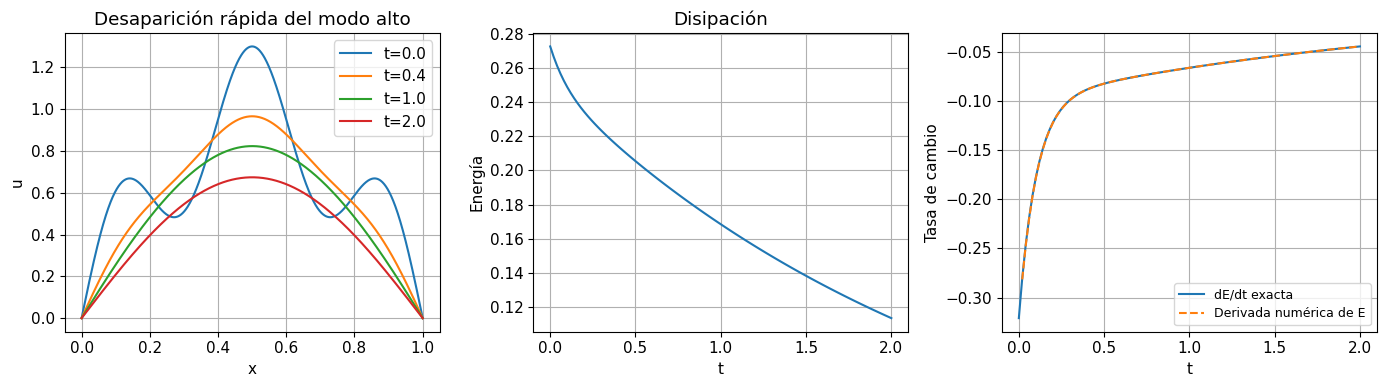

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
alpha = 0.02
x = np.linspace(0, 1, 1001)
t = np.linspace(0, 2, 101)
modos = np.array([1, 5]); amplitudes = np.array([1.0, 0.3])
coef = amplitudes[None, :]*np.exp(-alpha*t[:, None]*(np.pi*modos[None, :])**2)
U = coef @ np.sin(np.pi*modos[:, None]*x[None, :])
Ux = (coef*np.pi*modos[None, :]) @ np.cos(np.pi*modos[:, None]*x[None, :])
E = 0.5*trapezoid(U*U, x, axis=1)
disipacion = -alpha*trapezoid(Ux*Ux, x, axis=1)
dE_exact = -0.5*alpha*np.sum(coef*coef*(np.pi*modos[None, :])**2, axis=1)
assert np.allclose(disipacion, dE_exact, atol=1e-12)
assert np.all(np.diff(E) <= 1e-12)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for j in [0, 20, 50, 100]: axes[0].plot(x, U[j], label=f"t={t[j]:.1f}")
axes[0].set(xlabel="x", ylabel="u", title="Desaparición rápida del modo alto"); axes[0].legend()
axes[1].plot(t, E); axes[1].set(xlabel="t", ylabel="Energía", title="Disipación")
axes[2].plot(t, dE_exact, label="dE/dt exacta")
axes[2].plot(t[1:-1], np.gradient(E, t)[1:-1], "--", label="Derivada numérica de E")
axes[2].set(xlabel="t", ylabel="Tasa de cambio"); axes[2].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 3. Dependencia continua y difusión hacia atrás

En base seno, $u_m(T)=e^{-\alpha(m\pi)^2T}u_m(0)$. Si la perturbación inicial es el modo normalizado $\phi_m$, su norma es uno, pero la perturbación final tiene norma $e^{-\alpha(m\pi)^2T}\to0$.

Así, existen datos finales arbitrariamente pequeños que corresponden a cambios iniciales de tamaño uno. Un inverso continuo en $L^2$ no puede reconstruirlos de forma estable. La red que intenta hacerlo necesita información adicional, como una prior sobre condiciones iniciales o regularización; entrenar más no elimina esta pérdida de información del operador físico.

En el gráfico representaremos normas finales teóricas, no errores de un método numérico ni resultados de entrenamiento.

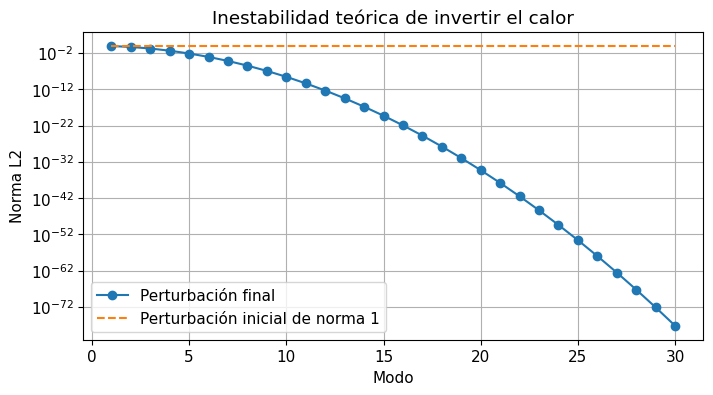

In [2]:
m = np.arange(1, 31)
T = 1.0
norma_final = np.exp(-alpha*(m*np.pi)**2*T)
fig, ax = plt.subplots()
ax.semilogy(m, norma_final, "o-", label="Perturbación final")
ax.semilogy(m, np.ones_like(m), "--", label="Perturbación inicial de norma 1")
ax.set(xlabel="Modo", ylabel="Norma L2", title="Inestabilidad teórica de invertir el calor")
ax.legend(); plt.show()

## 4. Ecuación elíptica con material discontinuo

Consideremos $-(\kappa(x)u')'=0$, $u(0)=0$, $u(1)=1$, con $\kappa=1$ a la izquierda de $1/2$ y $\kappa=2$ a la derecha. La solución es continua, pero su derivada cambia en la interfaz.

El flujo físico $q=-\kappa u'$ debe ser continuo. Como $\kappa u'=J$ constante,
$$1=u(1)-u(0)=J\int_0^1\frac{dx}{\kappa(x)}=J\left(\frac12+\frac14\right),\qquad J=\frac43.$$
Entonces $u=Jx$ en la primera mitad y $u=J[1/2+(x-1/2)/2]$ en la segunda. Una derivada clásica de segundo orden no describe cómodamente la interfaz, pero la formulación de flujo y la solución débil sí.

## 5. Formulación débil y coercividad

Con una función $v\in H_0^1(0,1)$,
$$\int_0^1\kappa u'v'\,dx=0.$$
Las condiciones no homogéneas se incorporan mediante una función de levantamiento que tiene los valores de frontera; el resto de la incógnita pertenece a $H_0^1$.

Si $0<\kappa_{\min}\le\kappa(x)\le\kappa_{\max}<\infty$, la forma bilineal es continua y coerciva en la norma de energía. Lax–Milgram establece existencia y unicidad para fuentes y condiciones compatibles. El coeficiente puede ser discontinuo sin impedir esta formulación.

La discretización siguiente utiliza coeficientes por intervalos y un balance de flujos entre nodos. La interfaz está alineada con la malla y la solución es lineal en cada material.

Error máximo interfaz alineada: 2.098321516541546e-14
Flujo físico medio (esperado -4/3): -1.3333333333333144


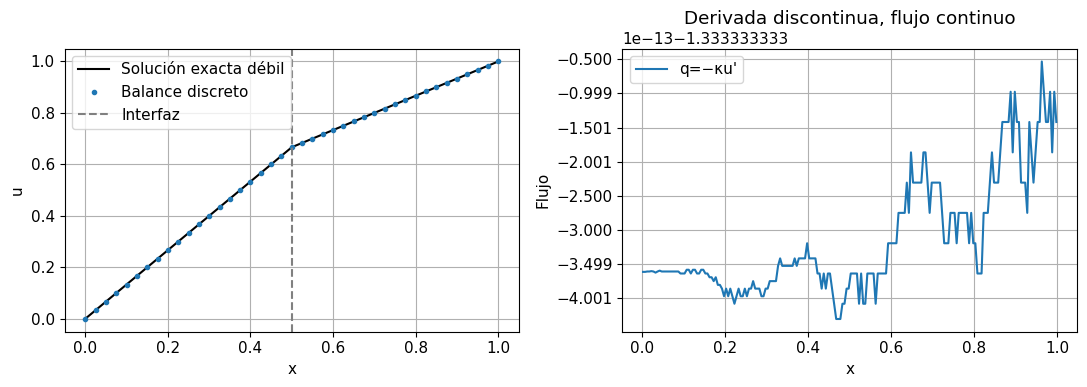

In [3]:
N = 200; h = 1/N
xn = np.linspace(0, 1, N+1)
xcaras = 0.5*(xn[:-1]+xn[1:])
kcaras = np.where(xcaras < 0.5, 1.0, 2.0)
diag = (kcaras[:-1]+kcaras[1:])/h**2
off = -kcaras[1:-1]/h**2
A = diags([off, diag, off], [-1, 0, 1], format="csc")
b = np.zeros(N-1); b[-1] += kcaras[-1]/h**2  # Frontera u(1)=1.
uh = np.r_[0.0, spsolve(A, b), 1.0]
J = 4/3
uex = np.where(xn <= 0.5, J*xn, J*(0.5+(xn-0.5)/2))
flujo = -kcaras*np.diff(uh)/h
print("Error máximo interfaz alineada:", np.max(np.abs(uh-uex)))
print("Flujo físico medio (esperado -4/3):", flujo.mean())
assert np.max(np.abs(uh-uex)) < 1e-10
assert np.max(np.abs(flujo+J)) < 1e-9
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(xn, uex, "k", label="Solución exacta débil")
axes[0].plot(xn[::5], uh[::5], "o", ms=3, label="Balance discreto")
axes[0].axvline(0.5, ls="--", color="gray", label="Interfaz")
axes[0].set(xlabel="x", ylabel="u"); axes[0].legend()
axes[1].plot(xcaras, flujo, label="q=−κu'")
axes[1].set(xlabel="x", ylabel="Flujo", title="Derivada discontinua, flujo continuo")
axes[1].legend(); plt.tight_layout(); plt.show()

## 6. Distribuciones y balances con discontinuidades

Una distribución actúa sobre funciones de prueba. La derivada distribucional de una función escalón es una delta; esa idea permite expresar cambios concentrados, interfaces y shocks. Una solución débil de una ley de conservación satisface la ecuación después de integrar contra funciones suaves, moviendo las derivadas a la prueba.

Para $u_t+f(u)_x=0$ y una prueba compactamente soportada, la identidad incluye
$$\int_0^\infty\!\int[u\varphi_t+f(u)\varphi_x]\,dx\,dt+\int u_0(x)\varphi(x,0)\,dx=0.$$
Ya no pedimos que $u_t$ y $u_x$ existan como funciones clásicas. La conservación integral, sin embargo, impone una velocidad específica a una discontinuidad.

## 7. Burgers y formación de shocks

Para Burgers, $f(u)=u^2/2$ y las características suaves viajan con velocidad $f'(u)=u$. Si valores mayores quedan detrás de valores menores, las características se alcanzan y puede formarse un shock.

Para un salto entre $u_L$ y $u_R$, Rankine–Hugoniot da
$$s=\frac{f(u_L)-f(u_R)}{u_L-u_R}=\frac{u_L+u_R}{2}.$$
Con $u_L=1$, $u_R=0$ obtenemos $s=1/2$. Esta condición conserva el balance, pero no selecciona por sí sola la solución física entre todas las soluciones débiles.

## 8. Entropía y rarefacción

Para flujo convexo, un shock admisible tiene características entrando en él: $u_L>s>u_R$. Cuando $u_L<u_R$, la solución admisible es una rarefacción, no un salto expansivo. Para datos $0$ a la izquierda y $1$ a la derecha en $x_0$,
$$u(x,t)=\begin{cases}0,&x<x_0,\\(x-x_0)/t,&x_0\le x\le x_0+t,\\1,&x>x_0+t.\end{cases}$$
La condición de entropía puede expresarse mediante desigualdades para entropías convexas. También surge como límite de viscosidad positiva $u_t+f(u)_x=\nu u_{xx}$ cuando $\nu\downarrow0$ en condiciones adecuadas.

Vamos a aproximar ambos problemas con un flujo de Rusanov, que incluye una disipación numérica relacionada con velocidades locales.

Error L1 shock: 0.003649453214165105
Error L1 rarefacción: 0.01094336045453046


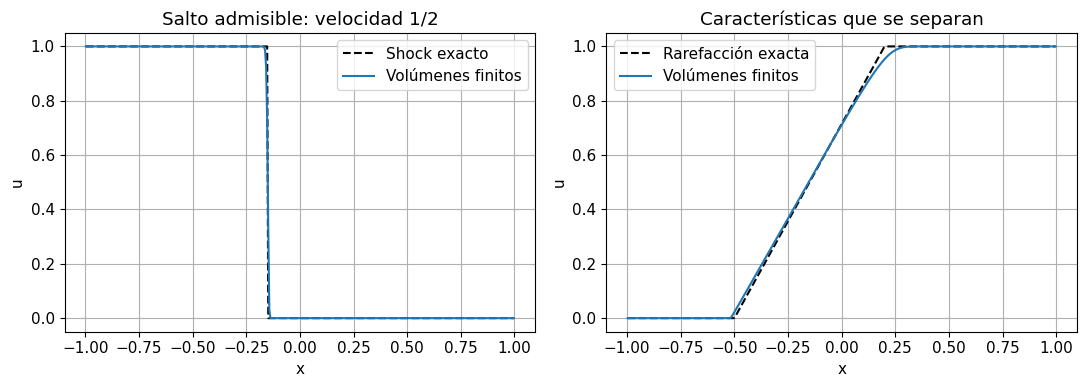

In [4]:
def burgers(uL, uR, x0=-0.5, final=0.7, N=400, cfl=0.45):
    dx = 2/N; xc = -1+(np.arange(N)+0.5)*dx
    u = np.where(xc < x0, float(uL), float(uR))
    masa_inicial = dx*u.sum(); ahora = 0.0
    historial = [(ahora, dx*u.sum())]
    while ahora < final-1e-14:
        velocidad = max(1e-12, np.max(np.abs(u)), abs(uL), abs(uR))
        dt = min(cfl*dx/velocidad, final-ahora)
        ext = np.r_[uL, u, uR]
        izquierda, derecha = ext[:-1], ext[1:]
        a = np.maximum(np.abs(izquierda), np.abs(derecha))
        flujo = 0.25*(izquierda**2+derecha**2)-0.5*a*(derecha-izquierda)
        u = u-dt/dx*(flujo[1:]-flujo[:-1])
        ahora += dt; historial.append((ahora, dx*u.sum()))
    return xc, u, np.array(historial), masa_inicial

xshock, us, hist_s, masa_s = burgers(1, 0)
xrar, ur, hist_r, masa_r = burgers(0, 1)
x0, tf = -0.5, 0.7
shock_exact = np.where(xshock < x0+0.5*tf, 1.0, 0.0)
raref_exact = np.clip((xrar-x0)/tf, 0, 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(xshock, shock_exact, "k--", label="Shock exacto")
axes[0].plot(xshock, us, label="Volúmenes finitos")
axes[0].set(xlabel="x", ylabel="u", title="Salto admisible: velocidad 1/2"); axes[0].legend()
axes[1].plot(xrar, raref_exact, "k--", label="Rarefacción exacta")
axes[1].plot(xrar, ur, label="Volúmenes finitos")
axes[1].set(xlabel="x", ylabel="u", title="Características que se separan"); axes[1].legend()
plt.tight_layout(); plt.show()
print("Error L1 shock:", (2/400)*np.sum(np.abs(us-shock_exact)))
print("Error L1 rarefacción:", (2/400)*np.sum(np.abs(ur-raref_exact)))

## 9. Conservación discreta y condición CFL

El método actualiza cada celda con la diferencia de dos flujos. Al sumar celdas, los flujos interiores se cancelan exactamente salvo redondeo. En un dominio abierto, masa cambia por flujo en las fronteras, así que **conservación no significa masa constante en cualquier problema**.

Para el shock de $1$ a $0$, el flujo de entrada menos salida es $f(1)-f(0)=1/2$, de modo que $M(t)=M(0)+t/2$ mientras los estados de frontera permanecen adecuados. Para rarefacción $0$ a $1$ el cambio es $-t/2$.

Usamos $\Delta t\max|u|/\Delta x\le0.45$. La condición CFL controla cuánto viaja información por paso; su forma precisa depende del esquema. Refinaremos malla y mediremos error $L^1$, una norma natural para discontinuidades; no esperamos error máximo pequeño en el punto exacto del salto.

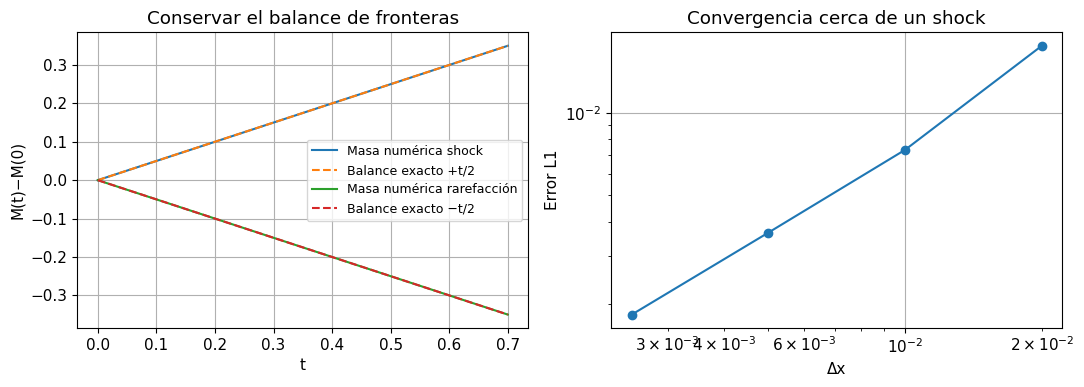

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist_s[:, 0], hist_s[:, 1]-masa_s, label="Masa numérica shock")
axes[0].plot(hist_s[:, 0], 0.5*hist_s[:, 0], "--", label="Balance exacto +t/2")
axes[0].plot(hist_r[:, 0], hist_r[:, 1]-masa_r, label="Masa numérica rarefacción")
axes[0].plot(hist_r[:, 0], -0.5*hist_r[:, 0], "--", label="Balance exacto −t/2")
axes[0].set(xlabel="t", ylabel="M(t)−M(0)", title="Conservar el balance de fronteras"); axes[0].legend(fontsize=9)
assert np.max(np.abs(hist_s[:, 1]-masa_s-0.5*hist_s[:, 0])) < 1e-10
Ns = [100, 200, 400, 800]
eL1 = []
for n in Ns:
    xx, uu, _, _ = burgers(1, 0, N=n)
    ex = np.where(xx < x0+0.5*tf, 1.0, 0.0)
    eL1.append(2/n*np.sum(np.abs(uu-ex)))
axes[1].loglog(2/np.array(Ns), eL1, "o-")
axes[1].set(xlabel="Δx", ylabel="Error L1", title="Convergencia cerca de un shock")
plt.tight_layout(); plt.show()

## 10. Qué verifica el experimento de Burgers

La solución numérica conserva balance de masa, representa velocidad correcta del shock y aproxima rarefacción. La difusión numérica suaviza el salto sobre varias celdas. Es una limitación de un esquema de primer orden y un motivo para estudiar reconstrucciones de mayor orden con limitadores.

Un gráfico de estado no basta: velocidad, balance y error al refinar aportan evidencias distintas. Tampoco nuestro experimento demuestra todas las condiciones de convergencia de Rusanov: sirve como caso verificable que ilustra consistencia y selección entrópica en un problema escalar.

## 11. Residuos físicos y normas adecuadas

Para Poisson, si $u$ es exacta y $v$ aproxima con la misma frontera, el error $e=v-u$ satisface $-e''=r$, donde $r=-v''-f$. En forma débil,
$$\|e'\|_{L^2}^2=\langle r,e\rangle\le\|r\|_{H^{-1}}\|e'\|_{L^2},$$
si usamos la norma energética en $H_0^1$ para definir su dual. De ahí $\|e'\|_{L^2}\le\|r\|_{H^{-1}}$. Si $r\in L^2$, Poincaré proporciona otra cota con una constante.

La teoría controla un residual como objeto continuo. Medirlo en puntos aislados no estima automáticamente esa norma. Frontera incorrecta agrega un término adicional; ecuación no coerciva o dinámica caótica requieren otro análisis.

## 12. Un residual que desaparece en colocación

Sea $u_*(x)=\sin\pi x$ y $v(x)=u_*(x)+\varepsilon\sin(M\pi x)$, con $M=20$. Ambas satisfacen frontera cero. Para $f=\pi^2\sin\pi x$,
$$r(x)=\varepsilon(M\pi)^2\sin(M\pi x).$$
En puntos $x_i=i/M$, el residual es exactamente cero en matemática exacta. Entre puntos puede ser grande. Una pérdida de colocación sobre esa malla fija no detecta el modo adicional. El ejemplo no depende de una red: revela un problema de muestreo de cualquier clase que pueda representar ese modo.

Máximo residual en colocación (redondeo): 4.4498897435060735e-13
Norma L2 continua aproximada del residual: 55.830913597111035
Error L2 de solución, exacto ε/√2: 0.014142135623730949
Error de derivada L2, exacto εMπ/√2: 0.8885765876316731


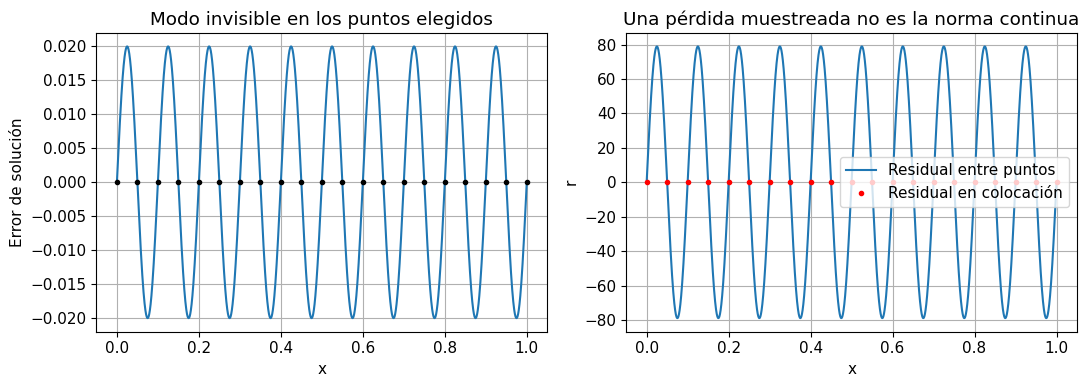

In [6]:
M, eps = 20, 0.02
xd = np.linspace(0, 1, 4001)
xc = np.linspace(0, 1, M+1)
u_star = np.sin(np.pi*xd)
v = u_star+eps*np.sin(M*np.pi*xd)
res_denso = eps*(M*np.pi)**2*np.sin(M*np.pi*xd)
res_col = eps*(M*np.pi)**2*np.sin(M*np.pi*xc)
print("Máximo residual en colocación (redondeo):", np.max(np.abs(res_col)))
print("Norma L2 continua aproximada del residual:", np.sqrt(trapezoid(res_denso**2, xd)))
print("Error L2 de solución, exacto ε/√2:", eps/np.sqrt(2))
print("Error de derivada L2, exacto εMπ/√2:", eps*M*np.pi/np.sqrt(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(xd, v-u_star)
axes[0].plot(xc, np.zeros_like(xc), "ko", ms=3)
axes[0].set(xlabel="x", ylabel="Error de solución", title="Modo invisible en los puntos elegidos")
axes[1].plot(xd, res_denso, label="Residual entre puntos")
axes[1].plot(xc, res_col, "ro", ms=3, label="Residual en colocación")
axes[1].set(xlabel="x", ylabel="r", title="Una pérdida muestreada no es la norma continua")
axes[1].legend(); plt.tight_layout(); plt.show()

## 13. Implicaciones para PINNs y operadores neuronales

Para una PINN, la suavidad de activación debe permitir derivadas usadas en el residual; soluciones con shocks pueden requerir formulaciones débiles, viscosidad o estrategias especializadas. Condiciones de frontera y entropía no se deducen de minimizar una ecuación en puntos arbitrarios.

Una PINN para materiales discontinuos puede usar condiciones de interfaz y residuales por subdominio. Un neural operator necesita aprender un mapa estable en el rango de parámetros considerado; si intenta invertir calor, la regularización forma parte del problema. Las normas de validación deben incluir cantidades relevantes como flujo, energía o error de rollout.

## 14. Un protocolo de validación matemática y numérica

Define espacio y cantidad de interés; verifica un caso suave con solución fabricada; prueba fronteras e interfaces; mide balance físico; refina malla o colocación; valida entre puntos y en datos nuevos. Para discontinuidades, usa una métrica que interprete correctamente desplazamiento de un shock.

El objetivo de una estimación de energía es ligar supuestos con error; el objetivo del experimento es mostrar si esos supuestos y comportamientos se conservan en el código. Ambos se complementan y ninguna gráfica aislada sustituye la otra parte.

| Inicio | Anterior |
| --- | --- |
| [🏠](../README.md) | [⏪](../21_MATEMATICA_MAS_AVANZADA/21_2_Analisis_funcional.ipynb) |